# Testing the eccentric correction of PhenomXHM against PhenomXE

Comparison of `PhenomXHM()` with the eccentric PN phase correction (Yunes et al. 2009, Eq. 4.28, truncated at $\mathcal{O}(e_0^8)$) and `PhenomXE()`, with no BGR correction.

The two models use different phase conventions, so waveforms are never compared point by point: the match is maximized over a constant phase (the `abs` of the overlap) and over a time shift, as in Eq. (4.4) of the XE paper (Ramos-Buades et al.) and Eq. (7.2) of the XHM paper (García-Quirós et al.).

In [1]:
using GWInference
using LinearAlgebra
using Interpolations # linear_interpolation, used for the noise curve
using Trapz
using Plots
using LaTeXStrings

In [2]:
# GW170608-like binary, same parameters as in testing_BGR_inclusion.ipynb
m1 = 11.0
m2 = 7.6
mc = (m1*m2)^(3/5) / (m1 + m2)^(1/5)
eta = m1*m2 / (m1 + m2)^2

chi_eff = 0.03
chi1 = chi_eff * (m1 + m2) / m1
chi2 = 0.0

dL = 0.32  # Gpc

e0 = 0.01      # initial eccentricity at the reference frequency f0
f0 = 10.0      # reference GW frequency [Hz]
meanAno = 0.0  # mean anomaly of PhenomXE at fRef (PhenomXHM has no mean anomaly)

0.0

# Testing eccentric XE and XHM with no BGR and $e_0 \neq 0$



In [3]:
# make sure it's the same starting point for both waves:
fmax = 512.0
f_grid = collect(range(f0, fmax, length=2000)) 

hp_XE_0, hc_XE_0 = hphc(PhenomXE(), f_grid, mc, eta, chi1, chi2, dL, 0.0, 0.0, meanAno; fRef=f0)
hp_XHM_0, hc_XHM_0 = hphc(PhenomXHM(), f_grid, mc, eta, chi1, chi2, dL, 0.0; e0=0.0, f0=f0)

fcut = min(_fcut(PhenomXE(), mc, eta, 0.0, 0.0),
               _fcut(PhenomXHM(), mc, eta, 0.0, 0.0)) # must be valid for both in ip integral otherwise it does not make sense so we take the minimum 
    isnothing(fmax) || (fcut = min(fcut, fmax))
print(fcut)

f_grid = f_grid[f_grid .<= fcut];

# getting the noise on the grid:

selected_detector = ETS
psdGrid = linear_interpolation(selected_detector.fNoise, selected_detector.psd, extrapolation_bc = 1.0)(f_grid); # copied from FisherMatrix_Internal

512.0

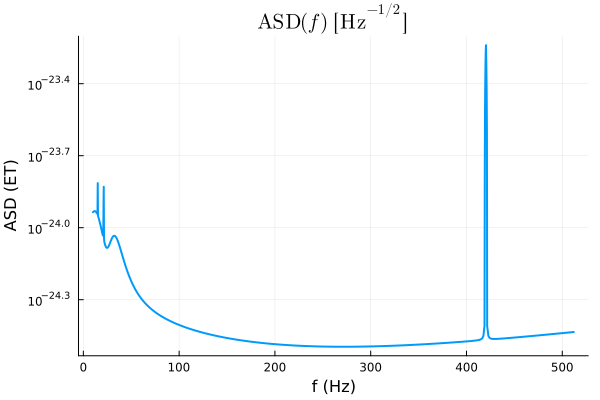

In [4]:
plot(f_grid, sqrt.(psdGrid),
     title = L"\mathrm{ASD}(f)\ [\mathrm{Hz}^{-1/2}]",
     xlabel = "f (Hz)",
     ylabel = "ASD (ET)",
     lw = 2,
     yscale = :log10,
     legend = false)

In [5]:
inner_product(a, b) = 4.0 * trapz(f_grid, a .* conj(b) ./ psdGrid) 

inner_product (generic function with 1 method)

In [6]:
hh_XE_prod = inner_product(hp_XE_0, hp_XE_0)
hh_XHM_prod = inner_product(hp_XHM_0, hp_XHM_0)

345044.79599909286 + 0.0im

In [7]:
println("rough SNR XE: ", sqrt(real(hh_XE_prod)))
println("rough SNR XHM: ", sqrt(real(hh_XHM_prod)))

rough SNR XE: 583.735967386108
rough SNR XHM: 587.4051378725699


In [8]:
extrema(psdGrid) # variance of psd

(1.0179699062824732e-49, 3.315391343383455e-47)

In [9]:
length(hp_XE_0) # checking the length of the array is correctly evaluated

2000

In [10]:
# if I take the abs value of the inner prod I can cancel out any possible dephasings due to the phase conventions: 

hh_XE_XHM_0_prod = abs(inner_product(hp_XE_0, hp_XHM_0))
faithfulness_0 = hh_XE_XHM_0_prod / sqrt(real(hh_XE_prod) * real(hh_XHM_prod))
println(1-faithfulness_0)

0.0005598100960919616


In [11]:
# now do the test with eccentric models
meanAno = 0.0
hp_XE_e, hc_XE_e = hphc(PhenomXE(), f_grid, mc, eta, chi1, chi2, dL, 0.0, 0.01, meanAno; fRef=f0)
hp_XHM_e, hc_XHM_e = hphc(PhenomXHM(), f_grid, mc, eta, chi1, chi2, dL, 0.0; e0=0.01, f0=f0);

In [12]:
e0_XHM = range(0.0005, 0.12, step = 1e-4)

norm_XE = real(inner_product(hp_XE_e, hp_XE_e))   # does not change in the loop
faithfulness_i = Float64[]
mismatch_i = Float64[]

for e0_i in e0_XHM
    hp_XHM_e_i, _ = hphc(PhenomXHM(), f_grid, mc, eta, chi1, chi2, dL, 0.0; e0 = e0_i, f0 = f0)
    ip_cross = abs(inner_product(hp_XE_e, hp_XHM_e_i))
    ip_norms = sqrt(norm_XE * real(inner_product(hp_XHM_e_i, hp_XHM_e_i)))
    push!(faithfulness_i, ip_cross / ip_norms)
    push!(mismatch_i, 1 - ip_cross / ip_norms)
end

i_min = argmin(mismatch_i)
println("minimum mismatch ", mismatch_i[i_min], " at e0_XHM = ", e0_XHM[i_min])

minimum mismatch 0.0004761725404814898 at e0_XHM = 0.0112


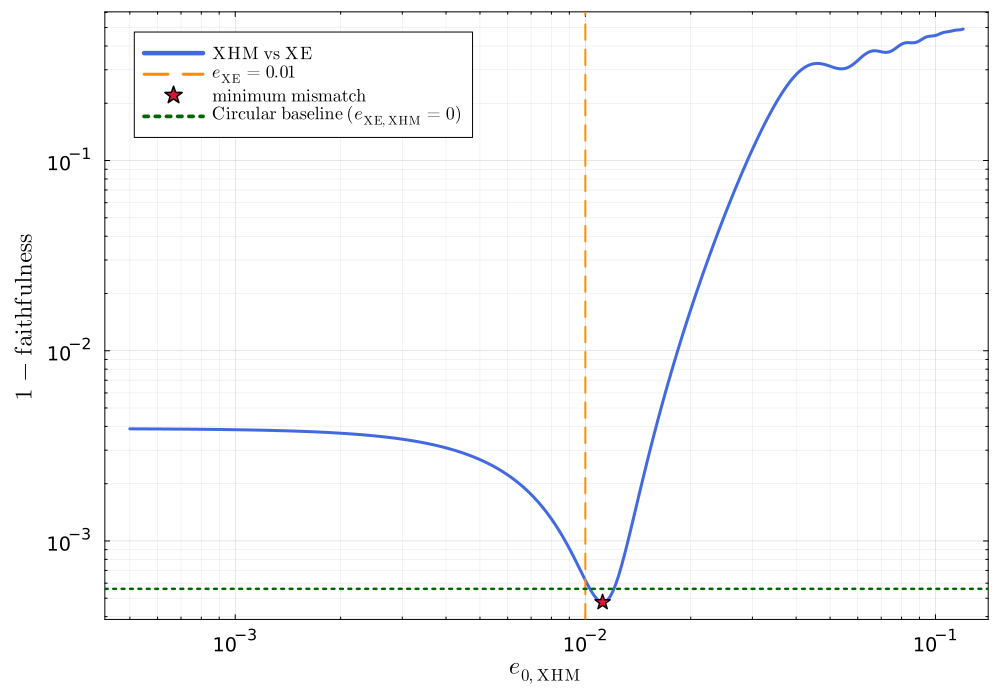

In [13]:
p = plot(e0_XHM, mismatch_i,
     xlabel = L"e_{0,\mathrm{XHM}}",
     ylabel = L"1 - \mathrm{faithfulness}",
     xscale = :log10,
     yscale = :log10,
     lw = 3,
     color = :royalblue,
     label = L"\mathrm{XHM}\ \mathrm{vs}\ \mathrm{XE}",
     legend = :topleft,
     size = (1000, 700),
     guidefontsize = 16,
     tickfontsize = 13,
     legendfontsize = 12,
     left_margin = 5Plots.mm,
     bottom_margin = 5Plots.mm,
     framestyle = :box,
     grid = :both,
     minorgrid = true)

vline!(p, [0.01],
     color = :darkorange,
     ls = :dash,
     lw = 2,
     label = L"e_{\mathrm{XE}} = 0.01")

scatter!(p, [e0_XHM[i_min]], [mismatch_i[i_min]],
     color = :crimson,
     markersize = 8,
     markershape = :star5,
     markerstrokecolor = :black,
     label = L"\mathrm{minimum \ mismatch}")

hline!(p, [5.6e-4],
     color = :darkgreen,
     ls = :dot,
     lw = 2.5,
     label = L"\mathrm{Circular\ baseline}\ (e_\mathrm{XE, XHM} =0)")

display(p)

### Scan at different $e_\mathrm{XE}$

Same scan as above, written as a function of $e_\mathrm{XE}$ and with the x-axis normalized: $e_{0,\mathrm{XHM}}/e_\mathrm{XE}$. If $e_0$ and $e$ are the same quantity, the minimum sits at a ratio of 1 for every $e_\mathrm{XE}$.

In [14]:
function scan_e0(e_XE, ratios; meanAno = 0.0)
    # XE is evaluated once at e_XE, XHM is re-evaluated for every e0 = ratio * e_XE
    hp_XE_e, _ = hphc(PhenomXE(), f_grid, mc, eta, chi1, chi2, dL, 0.0, e_XE, meanAno; fRef = f0)
    norm_XE = real(inner_product(hp_XE_e, hp_XE_e))   # does not change in the loop
    mismatch = Float64[]
    for r in ratios
        hp_XHM_i, _ = hphc(PhenomXHM(), f_grid, mc, eta, chi1, chi2, dL, 0.0; e0 = r * e_XE, f0 = f0)
        ip_cross = abs(inner_product(hp_XE_e, hp_XHM_i))
        ip_norms = sqrt(norm_XE * real(inner_product(hp_XHM_i, hp_XHM_i)))
        push!(mismatch, 1 - ip_cross / ip_norms)
    end
    return mismatch
end

scan_e0 (generic function with 1 method)

In [15]:
ratios = range(0.05, 3.0, step = 0.005)
e_XE_list = [0.01, 0.02, 0.05]

mismatch_scan = Dict{Float64, Vector{Float64}}()
for e_XE in e_XE_list
    mismatch_scan[e_XE] = scan_e0(e_XE, ratios)
    i = argmin(mismatch_scan[e_XE])
    println("e_XE = $e_XE: min mismatch = ", mismatch_scan[e_XE][i], " at e0_XHM/e_XE = ", ratios[i])
end

e_XE = 0.01: min mismatch = 0.0004761725404814898 at e0_XHM/e_XE = 1.12
e_XE = 0.02: min mismatch = 0.0006490884989819312 at e0_XHM/e_XE = 1.025
e_XE = 0.05: min mismatch = 0.0022579401343161276 at e0_XHM/e_XE = 0.99


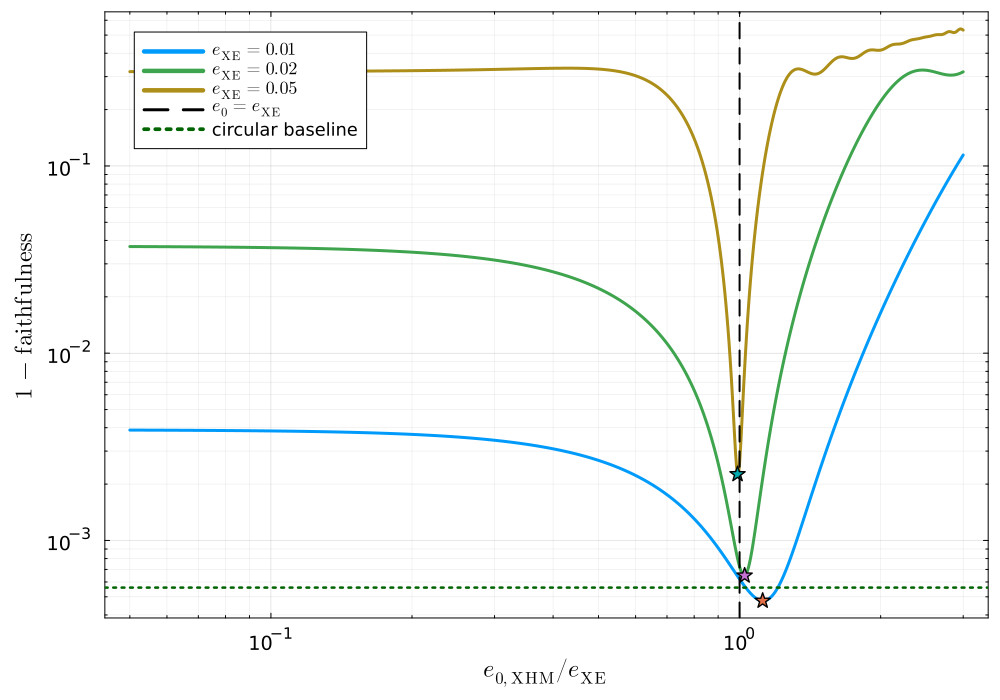

In [16]:
p = plot(xlabel = L"e_{0,\mathrm{XHM}} / e_{\mathrm{XE}}",
         ylabel = L"1 - \mathrm{faithfulness}",
         xscale = :log10, yscale = :log10,
         legend = :topleft, size = (1000, 700),
         guidefontsize = 16, tickfontsize = 13, legendfontsize = 12,
         left_margin = 5Plots.mm, bottom_margin = 5Plots.mm,
         framestyle = :box, grid = :both, minorgrid = true)

for e_XE in e_XE_list
    m = mismatch_scan[e_XE]
    plot!(p, ratios, m, lw = 3, label = L"e_\mathrm{XE} = %$e_XE")
    scatter!(p, [ratios[argmin(m)]], [minimum(m)], markershape = :star5, markersize = 8,
             markerstrokecolor = :black, label = "")
end

vline!(p, [1.0], color = :black, ls = :dash, lw = 2, label = L"e_0 = e_\mathrm{XE}")
hline!(p, [5.6e-4], color = :darkgreen, ls = :dot, lw = 2.5, label = "circular baseline")
display(p)

### Scan with a time shift

Same scan at $e_\mathrm{XE} = 0.01$, but the match is now maximized over a time shift $\tau$ as well as the constant phase (the `abs`), as in Eq. (4.4) of the XE paper and Eq. (7.2) of the XHM paper. The shift is applied to the XHM waveform as $e^{2\pi i f \tau}$.

In [17]:
τ_s = range(-8e-4, 8e-4, step = 1e-6)   # trial time shifts [s]: the baseline best value is about -6.5e-5 s

function match_tau(a, b, τ_s)

    # a time shift does not change the norm of b, so the norms are computed once
    ip_norms = sqrt(real(inner_product(a, a)) * real(inner_product(b, b)))

    mismatch_i = Float64[]

    for τ in τ_s
        b_τ = b .* exp.(2π * im .* f_grid .* τ) # apply shift to b waveform, make sure it's XHM -> convention with +
        faithfulness_i = abs(inner_product(a, b_τ)) / ip_norms
        push!(mismatch_i, 1 - faithfulness_i)
    end

    i = argmin(mismatch_i)
    return mismatch_i[i], τ_s[i]      # best mismatch and the shift where it occurs
end

match_tau (generic function with 1 method)

In [18]:
# tests of match_tau

# 1) known phase and shift tau = -3e-4: expected mismatch ~ 0
a_test = hp_XE_0
b_test = a_test .* exp(1im * 0.7) .* exp.(2π * im .* f_grid .* 3e-4)
println("known shift: ", match_tau(a_test, b_test, range(-1e-3, 1e-3, step = 1e-5)))

# 2) circular baseline
println("circular baseline: ", match_tau(hp_XE_0, hp_XHM_0, range(-1e-3, 1e-3, step = 5e-6)))

known shift: (-6.661338147750939e-16, -0.0003)
circular baseline: (6.147423588753753e-5, -6.5e-5)


In [19]:
function scan_e0_tau(e_XE, ratios, τ_s; meanAno = 0.0)
    # XE is evaluated once at e_XE, XHM is re-evaluated for every e0 = ratio * e_XE
    hp_XE_e, _ = hphc(PhenomXE(), f_grid, mc, eta, chi1, chi2, dL, 0.0, e_XE, meanAno; fRef = f0) # find the waveform -> 
    mismatch = Float64[] # declare mismatch and best time shift
    best_τ = Float64[]

    for r in ratios
        hp_XHM_i, _ = hphc(PhenomXHM(), f_grid, mc, eta, chi1, chi2, dL, 0.0; e0 = r * e_XE, f0 = f0) # again evaluate the XHM e-waveform
        m, τ = match_tau(hp_XE_e, hp_XHM_i, τ_s) # return the matching tau shift for each of the eccentricity vals
        push!(mismatch, m)
        push!(best_τ, τ)
    end
    return mismatch, best_τ # return mismatch value and best tau found for different e_XE / e_XHM
end

ratios_τ = range(0.2, 3.0, step = 0.01) # still ratios of e_XE / e_XHM
mismatch_τ, best_τ = scan_e0_tau(0.01, ratios_τ, τ_s)

i = argmin(mismatch_τ)
println("with time shift τ: min mismatch = ", mismatch_τ[i], " at e0_XHM/e_XE = ", ratios_τ[i])
println("at ratio 1: ", mismatch_τ[argmin(abs.(ratios_τ .- 1.0))])
# if the best tau sits on an edge of τ_s, the range is too narrow --> Claude :)
println("best tau between ", minimum(best_τ), " and ", maximum(best_τ), "   (scan edges: ", first(τ_s), ", ", last(τ_s), ")")

with time shift τ: min mismatch = 0.0001294784396531634 at e0_XHM/e_XE = 1.04
at ratio 1: 0.00014489996010247364
best tau between -0.000117 and 0.00032   (scan edges: -0.0008, 0.0008)


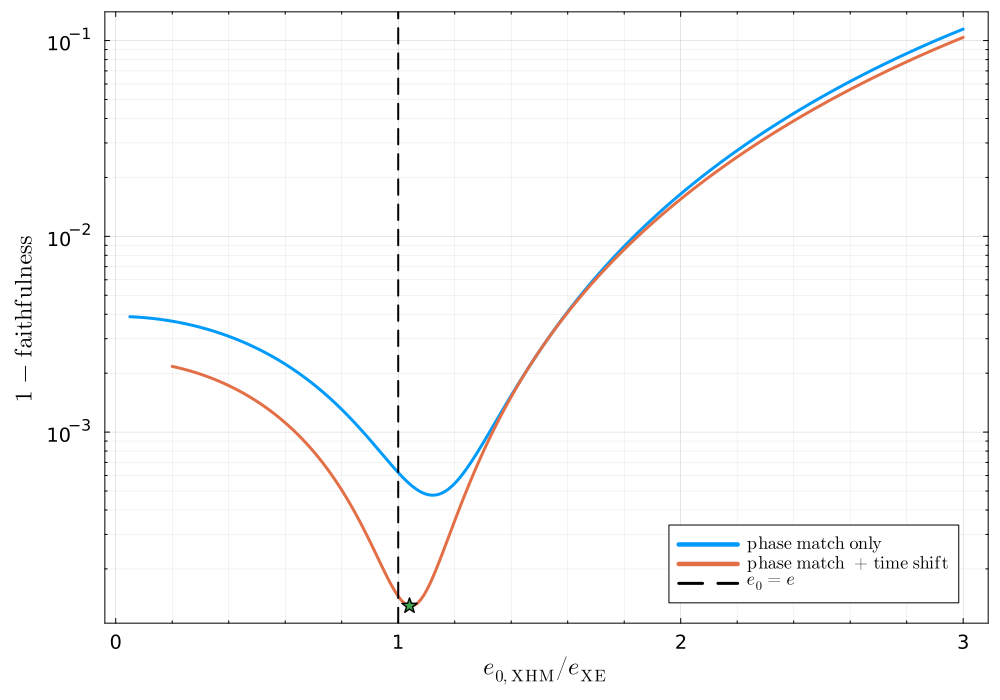

In [20]:
p = plot(xlabel = L"e_{0,\mathrm{XHM}} / e_{\mathrm{XE}}",
         ylabel = L"1 - \mathrm{faithfulness}",
         yscale = :log10,
         legend = :bottomright, size = (1000, 700),
         guidefontsize = 16, tickfontsize = 13, legendfontsize = 12,
         left_margin = 5Plots.mm, bottom_margin = 5Plots.mm,
         framestyle = :box, grid = :both, minorgrid = true)

# abs only (previous scan) and abs + time shift
plot!(p, ratios, mismatch_scan[0.01], lw = 3, label = L"\mathrm{phase\ match\ only}")
plot!(p, ratios_τ, mismatch_τ, lw = 3, label = L"\mathrm{phase\ match\ + time\ shift}")
scatter!(p, [ratios_τ[argmin(mismatch_τ)]], [minimum(mismatch_τ)], markershape = :star5, markersize = 8,
         markerstrokecolor = :black, label = "")

vline!(p, [1.0], color = :black, ls = :dash, lw = 2, label = L"e_0 = e")
#plot!(p, xlims = (0.7, 1.4))
display(p)

### Scan with a time shift at $e_\mathrm{XE} = 0.02$ and $0.05$

Same scan as at $e_\mathrm{XE} = 0.01$ (same `τ_s` and `ratios_τ`), repeated for the two larger eccentricities. If $e_0$ and $e$ are the same quantity the minimum should sit at a ratio of 1 for every $e_\mathrm{XE}$. At larger $e$ the dephasing grows as $e^2$, so the valley is narrower and the minimum is better determined.

In [21]:
e_XE_list_τ = [0.02, 0.05]

# the 0.01 result is already computed above
mismatch_τ_scan = Dict{Float64, Vector{Float64}}(0.01 => mismatch_τ)
best_τ_scan = Dict{Float64, Vector{Float64}}(0.01 => best_τ)

for e_XE in e_XE_list_τ
    mismatch_τ_scan[e_XE], best_τ_scan[e_XE] = scan_e0_tau(e_XE, ratios_τ, τ_s)

    i = argmin(mismatch_τ_scan[e_XE])
    println("e_XE = $e_XE, with time shift τ: min mismatch = ", mismatch_τ_scan[e_XE][i], " at e0_XHM/e_XE = ", ratios_τ[i])
    println("   at ratio 1: ", mismatch_τ_scan[e_XE][argmin(abs.(ratios_τ .- 1.0))])
    # if the best tau sits on an edge of τ_s, the range is too narrow
    println("   best tau between ", minimum(best_τ_scan[e_XE]), " and ", maximum(best_τ_scan[e_XE]), "   (scan edges: ", first(τ_s), ", ", last(τ_s), ")")
end

e_XE = 0.02, with time shift τ: min mismatch = 0.0003507876247238473 at e0_XHM/e_XE = 1.0
   at ratio 1: 0.0003507876247238473
   best tau between -0.000259 and 0.000429   (scan edges: -0.0008, 0.0008)
e_XE = 0.05, with time shift τ: min mismatch = 0.002022508905335507 at e0_XHM/e_XE = 0.99
   at ratio 1: 0.00254955893941311
   best tau between -0.000532 and 0.00044   (scan edges: -0.0008, 0.0008)


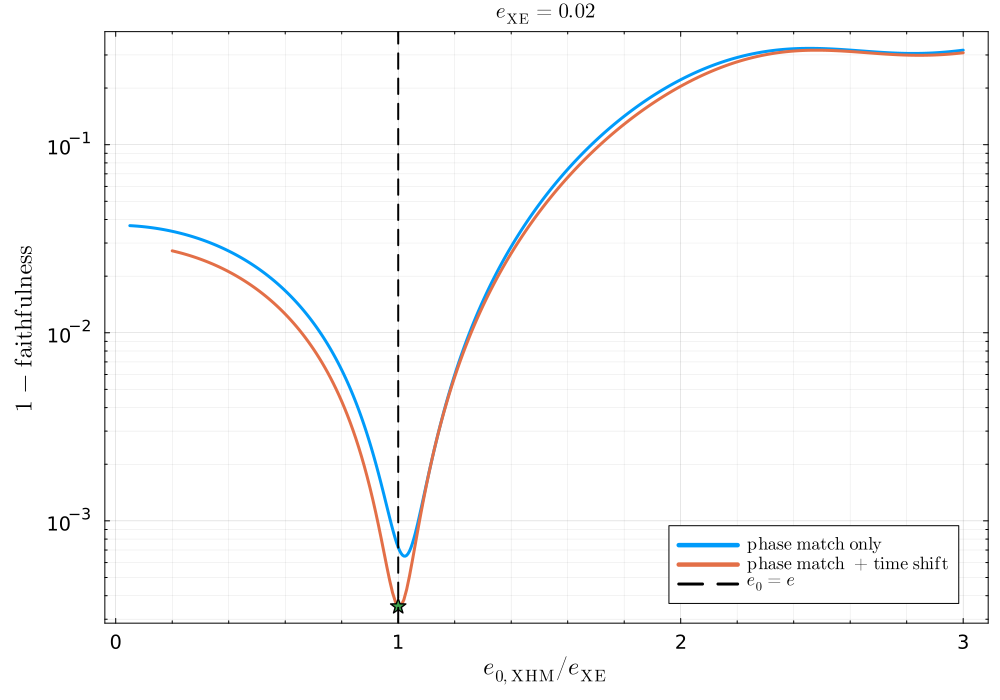

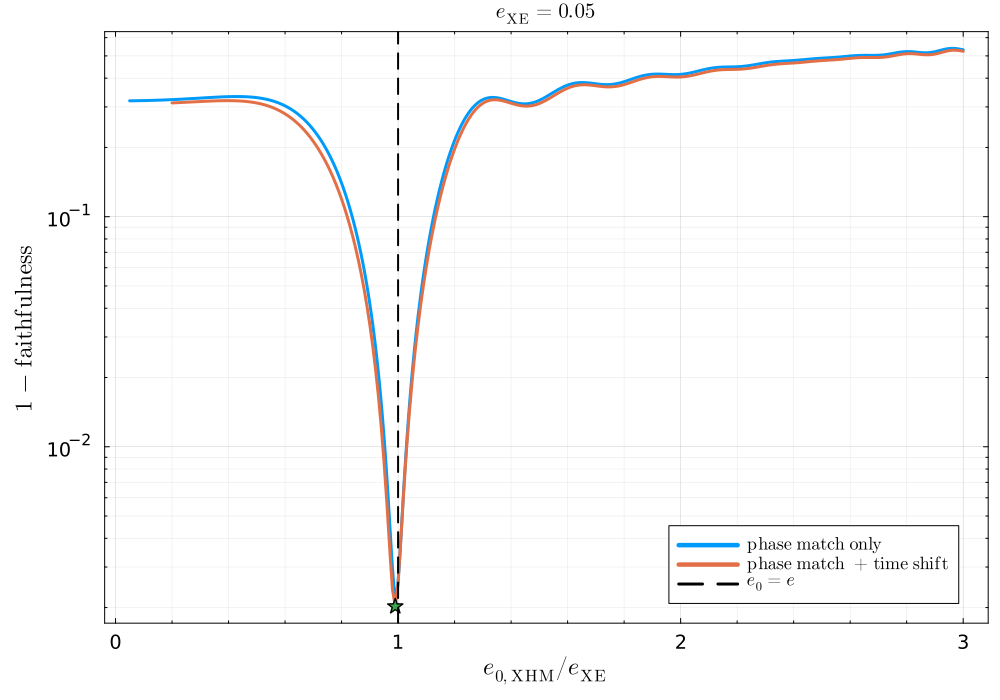

In [22]:
# one plot per e_XE, same style as above: phase match only (previous scan) vs phase match + time shift
for e_XE in e_XE_list_τ
    p = plot(xlabel = L"e_{0,\mathrm{XHM}} / e_{\mathrm{XE}}",
             ylabel = L"1 - \mathrm{faithfulness}",
             title = L"e_\mathrm{XE} = %$e_XE",
             yscale = :log10,
             legend = :bottomright, size = (1000, 700),
             guidefontsize = 16, tickfontsize = 13, legendfontsize = 12,
             left_margin = 5Plots.mm, bottom_margin = 5Plots.mm,
             framestyle = :box, grid = :both, minorgrid = true)

    plot!(p, ratios, mismatch_scan[e_XE], lw = 3, label = L"\mathrm{phase\ match\ only}")
    plot!(p, ratios_τ, mismatch_τ_scan[e_XE], lw = 3, label = L"\mathrm{phase\ match\ + time\ shift}")
    scatter!(p, [ratios_τ[argmin(mismatch_τ_scan[e_XE])]], [minimum(mismatch_τ_scan[e_XE])], markershape = :star5, markersize = 8,
             markerstrokecolor = :black, label = "")

    vline!(p, [1.0], color = :black, ls = :dash, lw = 2, label = L"e_0 = e")
    display(p)
end

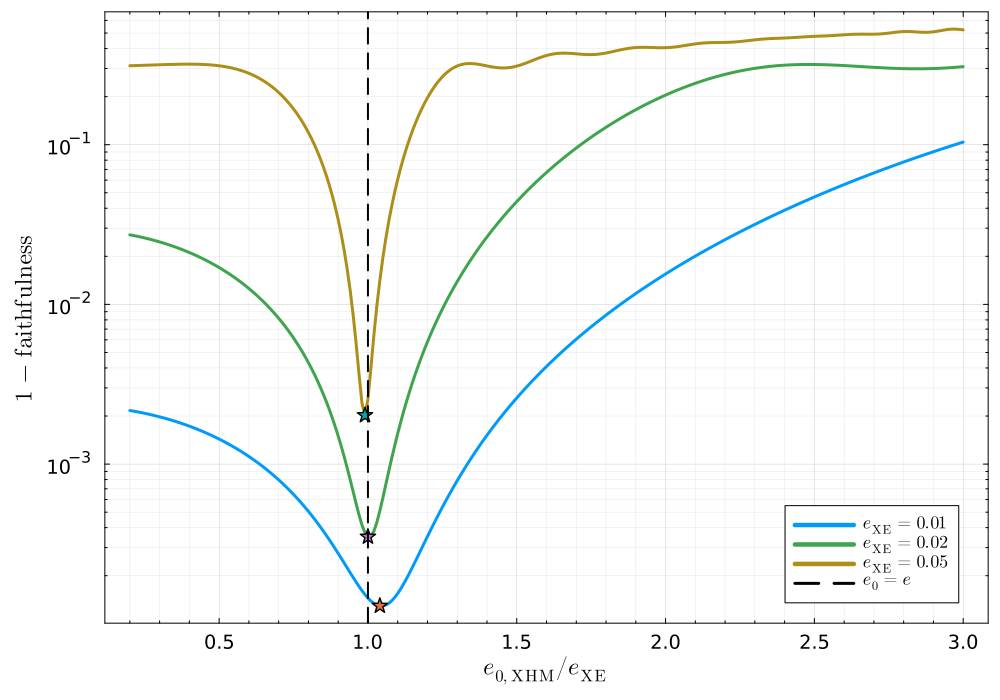

In [23]:
# the three eccentricities together, phase match + time shift
p = plot(xlabel = L"e_{0,\mathrm{XHM}} / e_{\mathrm{XE}}",
         ylabel = L"1 - \mathrm{faithfulness}",
         yscale = :log10,
         legend = :bottomright, size = (1000, 700),
         guidefontsize = 16, tickfontsize = 13, legendfontsize = 12,
         left_margin = 5Plots.mm, bottom_margin = 5Plots.mm,
         framestyle = :box, grid = :both, minorgrid = true)

for e_XE in sort(collect(keys(mismatch_τ_scan)))
    m = mismatch_τ_scan[e_XE]
    plot!(p, ratios_τ, m, lw = 3, label = L"e_\mathrm{XE} = %$e_XE")
    scatter!(p, [ratios_τ[argmin(m)]], [minimum(m)], markershape = :star5, markersize = 8,
             markerstrokecolor = :black, label = "")
end

vline!(p, [1.0], color = :black, ls = :dash, lw = 2, label = L"e_0 = e")
display(p)

### Test 1: mean anomaly of XE

XE depends on the mean anomaly $l$ at `fRef`, XHM does not. All earlier scans used $l = 0$. If the offset of the best $e_0$ depends on $l$, part of it comes from this arbitrary choice.

In [24]:
# e0=0.01
ratios_ma=range(0.6, 1.5, step = 0.01)
τ_s = range(-0.0008, 0.0008; step=4.0e-6)

meanAno_list = [0.0, π/2, π, 3π/2]

mismatch_ma = Dict{Float64, Vector{Float64}}()
for ma in meanAno_list
    mismatch_ma[ma], _ = scan_e0_tau(0.01, ratios_ma, τ_s_ma; meanAno = ma)
end

print_scan_table("e_XE = 0.01, meanAno:", meanAno_list, mismatch_ma, ratios_ma)

LoadError: UndefVarError: `τ_s_ma` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

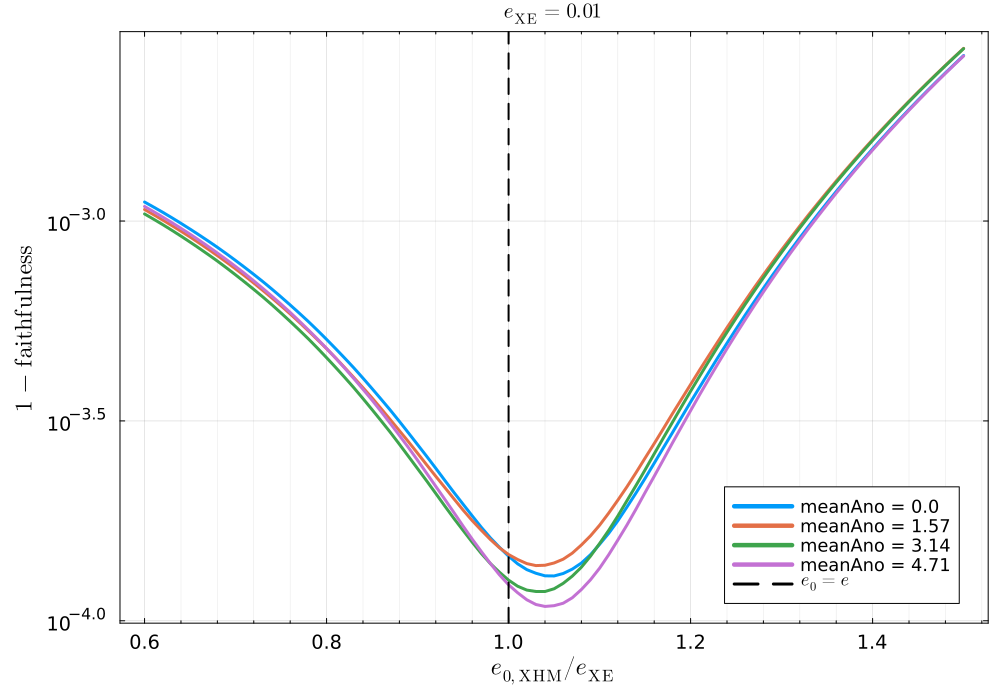

"/Users/nicolegrillo/Desktop/GW-envs/mean_ano01.png"

In [ ]:
p = plot(xlabel = L"e_{0,\mathrm{XHM}} / e_{\mathrm{XE}}", ylabel = L"1 - \mathrm{faithfulness}",
         yscale = :log10, legend = :bottomright, size = (1000, 700),
         title = L"e_\mathrm{XE} = 0.01", 
         guidefontsize = 16, tickfontsize = 13, legendfontsize = 12,
         left_margin = 5Plots.mm, bottom_margin = 5Plots.mm,
         framestyle = :box, grid = :both, minorgrid = true)
for ma in meanAno_list
    plot!(p, ratios_ma, mismatch_ma[ma], lw = 3, label = "meanAno = $(round(ma, digits = 2))")
end
vline!(p, [1.0], color = :black, ls = :dash, lw = 2, label = L"e_0 = e")
display(p)

savefig(p, "~/Desktop/GW-envs/mean_ano01.png")

In [ ]:
# e0=0.02

mismatch_ma2 = Dict{Float64, Vector{Float64}}()
for ma in meanAno_list
    mismatch_ma2[ma], _ = scan_e0_tau(0.02, ratios_ma, τ_s_ma; meanAno = ma)
end

print_scan_table("e_XE = 0.02, meanAno:", meanAno_list, mismatch_ma2, ratios_ma)

e_XE = 0.02, meanAno:   best ratio (parabola)   min mismatch   mismatch at ratio 1
  0.0           1.004         0.000351       0.000351
  1.5708        1.004         0.000392       0.000392
  3.1416        0.998         0.000386       0.000386
  4.7124        0.998         0.000356       0.000356


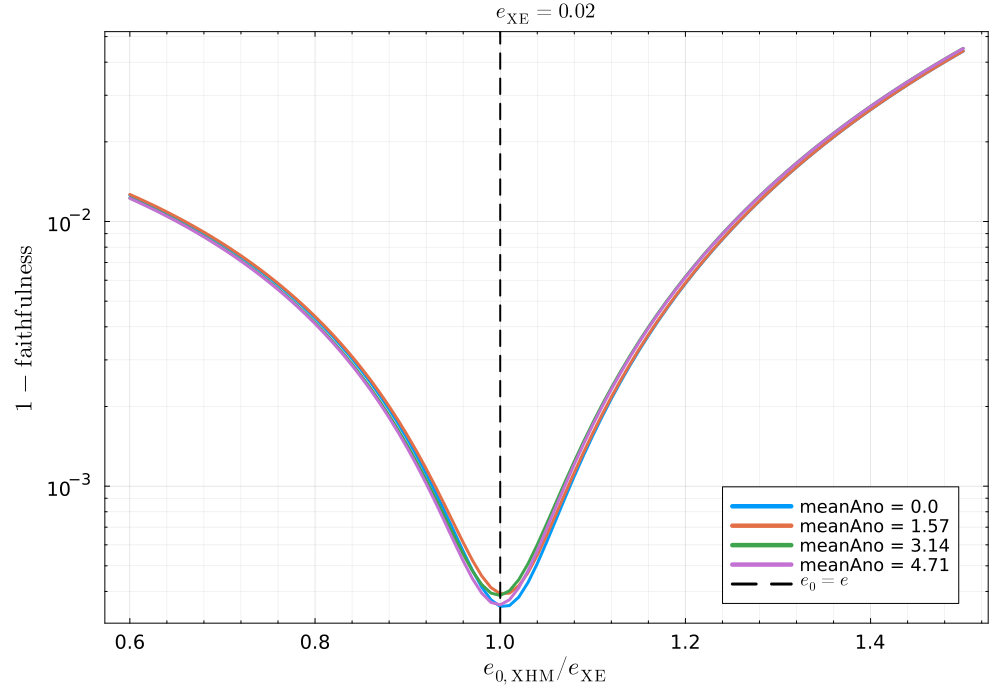

"/Users/nicolegrillo/Desktop/GW-envs/mean_ano02.png"

In [ ]:
p = plot(xlabel = L"e_{0,\mathrm{XHM}} / e_{\mathrm{XE}}", ylabel = L"1 - \mathrm{faithfulness}",
         yscale = :log10, legend = :bottomright, size = (1000, 700),
         title = L"e_\mathrm{XE} = 0.02", 
         guidefontsize = 16, tickfontsize = 13, legendfontsize = 12,
         left_margin = 5Plots.mm, bottom_margin = 5Plots.mm,
         framestyle = :box, grid = :both, minorgrid = true)
for ma in meanAno_list
    plot!(p, ratios_ma, mismatch_ma2[ma], lw = 3, label = "meanAno = $(round(ma, digits = 2))")
end
vline!(p, [1.0], color = :black, ls = :dash, lw = 2, label = L"e_0 = e")
display(p)

savefig(p, "~/Desktop/GW-envs/mean_ano02.png")

In [ ]:
# e0=0.05

mismatch_ma3 = Dict{Float64, Vector{Float64}}()
for ma in meanAno_list
    mismatch_ma3[ma], _ = scan_e0_tau(0.05, ratios_ma, τ_s_ma; meanAno = ma)
end

print_scan_table("e_XE = 0.05, meanAno:", meanAno_list, mismatch_ma3, ratios_ma)

e_XE = 0.05, meanAno:   best ratio (parabola)   min mismatch   mismatch at ratio 1
  0.0           0.989          0.00202        0.00255
  1.5708        0.989          0.00222        0.00277
  3.1416        0.989           0.0021         0.0026
  4.7124        0.989           0.0022        0.00272


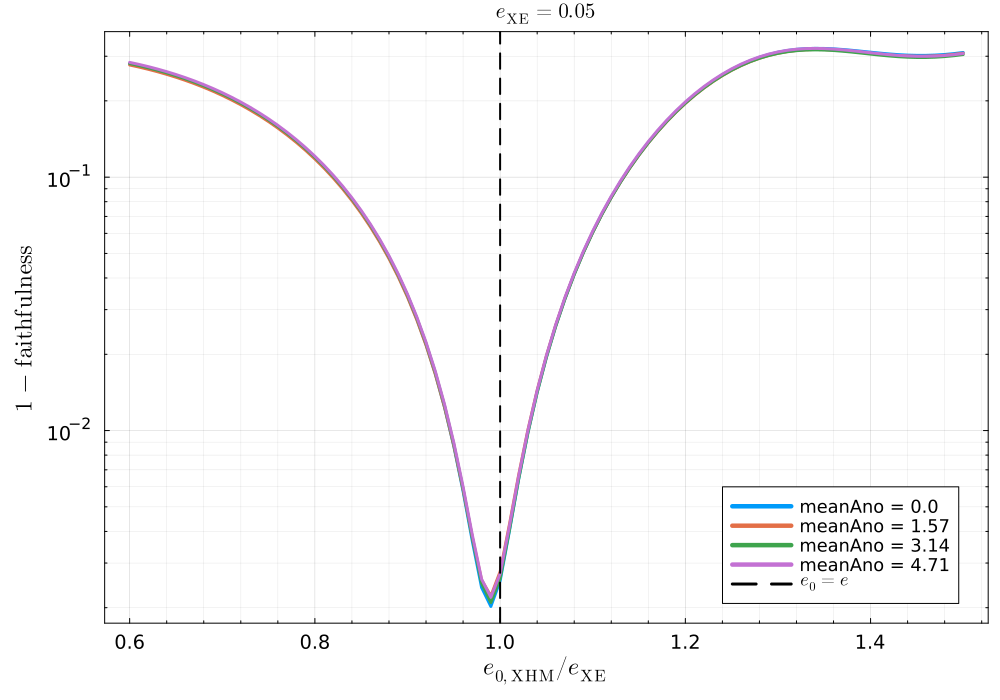

"/Users/nicolegrillo/Desktop/GW-envs/mean_ano05.png"

In [ ]:
p = plot(xlabel = L"e_{0,\mathrm{XHM}} / e_{\mathrm{XE}}", ylabel = L"1 - \mathrm{faithfulness}",
         yscale = :log10, legend = :bottomright, size = (1000, 700),
         title = L"e_\mathrm{XE} = 0.05",
         guidefontsize = 16, tickfontsize = 13, legendfontsize = 12,
         left_margin = 5Plots.mm, bottom_margin = 5Plots.mm,
         framestyle = :box, grid = :both, minorgrid = true)
for ma in meanAno_list
    plot!(p, ratios_ma, mismatch_ma3[ma], lw = 3, label = "meanAno = $(round(ma, digits = 2))")
end
vline!(p, [1.0], color = :black, ls = :dash, lw = 2, label = L"e_0 = e")
display(p)

savefig(p, "~/Desktop/GW-envs/mean_ano05.png")

### Test 2: lower eccentricities

If the shift of the best $e_0$ is the compensation of the circular disagreement, it should grow as $e_\mathrm{XE}$ decreases, because the eccentric dephasing ($\propto e^2$) becomes smaller compared with the baseline difference between the models. At very low $e$ the minimum is not well determined, since the whole curve is close to the circular baseline.

In [ ]:
e_XE_low = [0.0025, 0.005, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2]

mismatch_low = Dict{Float64, Vector{Float64}}()
for e_XE in e_XE_low
    mismatch_low[e_XE], _ = scan_e0_tau(e_XE, ratios_ma, τ_s_ma)
end

print_scan_table("meanAno = 0, e_XE:", e_XE_low, mismatch_low, ratios_ma)
println("circular baseline (e = 0 in both, same time shifts): ", match_tau(hp_XE_0, hp_XHM_0, τ_s_ma)[1])

meanAno = 0, e_XE:   best ratio (parabola)   min mismatch   mismatch at ratio 1
  0.0025          1.5          5.06e-5         6.9e-5
  0.005          1.19           6.7e-5        8.59e-5
  0.01          1.045         0.000129       0.000145
  0.02          1.004         0.000351       0.000351
  0.05          0.989          0.00202        0.00255
  0.1           0.987          0.00888         0.0199
  0.15          0.987           0.0216         0.0764
  0.2           0.987           0.0466          0.202
circular baseline (e = 0 in both, same time shifts): 6.132814945036813e-5


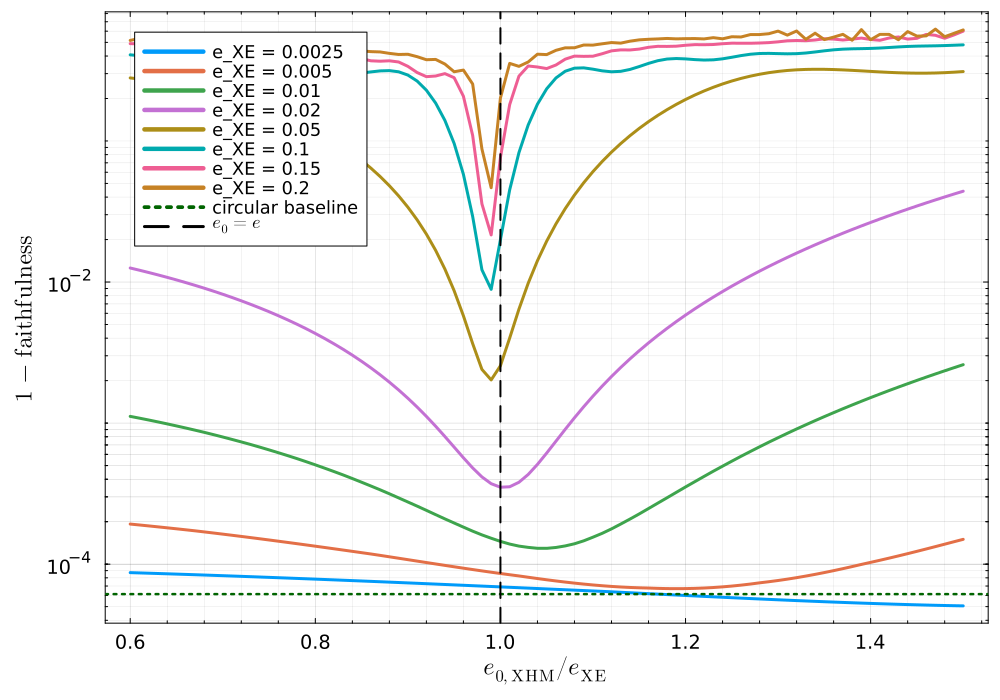

"/Users/nicolegrillo/Desktop/GW-envs/varying_eXE.png"

In [ ]:
p = plot(xlabel = L"e_{0,\mathrm{XHM}} / e_{\mathrm{XE}}", ylabel = L"1 - \mathrm{faithfulness}",
         yscale = :log10, legend = :topleft, size = (1000, 700),
         guidefontsize = 16, tickfontsize = 13, legendfontsize = 12,
         left_margin = 5Plots.mm, bottom_margin = 5Plots.mm,
         framestyle = :box, grid = :both, minorgrid = true)
for e_XE in e_XE_low
    plot!(p, ratios_ma, mismatch_low[e_XE], lw = 3, label = "e_XE = $e_XE")
end
hline!(p, [match_tau(hp_XE_0, hp_XHM_0, τ_s_ma)[1]], color = :darkgreen, ls = :dot, lw = 2.5, label = "circular baseline")
vline!(p, [1.0], color = :black, ls = :dash, lw = 2, label = L"e_0 = e")
display(p)

savefig(p, "~/Desktop/GW-envs/varying_eXE.png")

## Mismatch over the parameter space at $e_{0,\mathrm{XHM}} = e_\mathrm{XE}$

Mismatch between `PhenomXE` (eccentricity $e$) and `PhenomXHM` with the eccentric correction ($e_0 = e$, no optimization over $e_0$), as a function of the mass ratio $q$ and the effective spin $\chi_\mathrm{eff}$, for $e = 0.01, 0.02, 0.05$. For each $(q, \chi_\mathrm{eff})$ the value shown is the **maximum over the total mass** in $[20, 200]\,M_\odot$ (12 log-spaced values), as in the eccentric comparisons of the XE paper (mismatch maximized over a phase offset and a time shift for each mass, then the maximum over the mass range).

- The mass ratio goes up to $q = 17.5$: GWJulia's `PhenomXHM` prints a warning ("extreme mass ratio limit, model not implemented yet") below $\eta = 0.05$, i.e. for $q > 17.9$.
- Face-on ($\iota = 0$), plus polarization, ETS noise, band from $f_0 = 10$ Hz to $\min(512\ \mathrm{Hz}, f_\mathrm{cut})$, `meanAno = 0` for XE, spins $\chi_1 = \chi_2 = \chi_\mathrm{eff}$.
- Except at $q = 1$ with equal spins, XHM includes higher modes (at $\iota = 0$ the $(3,2)$ mode survives), so part of the mismatch is not due to eccentricity. The circular case ($e = 0$) is the reference for that.
- Points where `PhenomXE` fails or its ODE solution is not converged (the amplitude changes by more than 1% when only the solver tolerance changes) are excluded. A pixel is blank if no mass was usable (this happens at large $q$ with large positive spin, where the XAS amplitude coefficients fail).

In [ ]:
function mismatch_point_ecc(M, q, chi1, chi2; e, meanAno = 0.0, f0 = 10.0, fmax = 512.0, npts = 2000,
                            τ_max_M = 10.0, detector = ETS, xe_tol = 1e-2)
    # XE(e) against XHM(e0 = e) for a binary with total mass M [Msun] and q = m1/m2 >= 1, maximized over a
    # constant phase and a time shift. Returns NaN as mismatch if the XE waveform is not converged.
    m1 = M * q / (1 + q)
    m2 = M / (1 + q)
    mc = (m1 * m2)^(3/5) / M^(1/5)
    eta = m1 * m2 / M^2

    fcut = min(_fcut(PhenomXE(), mc, eta, 0.0, 0.0), _fcut(PhenomXHM(), mc, eta, 0.0, 0.0), fmax)
    f = collect(range(f0, fcut, length = npts))
    psd = linear_interpolation(detector.fNoise, detector.psd, extrapolation_bc = 1.0)(f)
    ip(x, y) = 4.0 * trapz(f, x .* conj(y) ./ psd)

    hp_XE, _ = hphc(PhenomXE(), f, mc, eta, chi1, chi2, 0.32, 0.0, e, meanAno; fRef = f0)
    # PhenomXE integrates an ODE: if the amplitude changes when only the tolerance changes, it is not converged
    hp_XE_check, _ = hphc(PhenomXE(), f, mc, eta, chi1, chi2, 0.32, 0.0, e, meanAno; fRef = f0, rtol = 1e-10, atol = 1e-10)
    xe_change = norm(abs.(hp_XE) .- abs.(hp_XE_check)) / norm(abs.(hp_XE))
    xe_change < xe_tol || return (mismatch = NaN, τ = NaN, at_edge = false)

    hp_XHM, _ = hphc(PhenomXHM(), f, mc, eta, chi1, chi2, 0.32, 0.0; e0 = e, f0 = f0)
    ip_norms = sqrt(real(ip(hp_XE, hp_XE)) * real(ip(hp_XHM, hp_XHM)))

    # time shifts scale with the total mass; if the best one sits on the edge of the range, the range is doubled
    τ_step = 0.03 / (2π * fcut)
    τ_max = τ_max_M * M * GMsun_over_c3
    best = Inf; τ_best = 0.0; at_edge = true
    for attempt in 1:5
        τ_s = range(-τ_max, τ_max, step = τ_step)
        best = Inf
        for τ in τ_s
            m = 1 - abs(ip(hp_XE, hp_XHM .* exp.(2π * im .* f .* τ))) / ip_norms
            if m < best
                best = m; τ_best = τ
            end
        end
        at_edge = (τ_best == first(τ_s)) || (τ_best == last(τ_s))
        at_edge || break
        τ_max *= 2
    end
    return (mismatch = best, τ = τ_best, at_edge = at_edge)
end

function mismatch_map_ecc(qs, chis, Ms; e, kwargs...)
    # maximum over the usable masses at each (q, chi_eff), with chi1 = chi2 = chi_eff
    zmax = fill(NaN, length(chis), length(qs))
    n_unusable = 0
    for (i, q) in enumerate(qs), (j, chi) in enumerate(chis)
        vals = Float64[]
        for M in Ms
            m = try
                mismatch_point_ecc(M, q, chi, chi; e = e, kwargs...).mismatch
            catch err
                NaN
            end
            isnan(m) ? (n_unusable += 1) : push!(vals, m)
        end
        isempty(vals) || (zmax[j, i] = maximum(vals))
    end
    return zmax, n_unusable
end

mismatch_map_ecc (generic function with 1 method)

In [ ]:
qs_ecc = [1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0, 12.0, 15.0, 17.5]   # PhenomXHM in GWJulia warns below eta = 0.05 (q > 17.9)
chis_ecc = collect(range(-0.9, 0.9, length = 13))
Ms_ecc = 10 .^ range(log10(20.0), log10(200.0), length = 12)
e_list_ecc = [0.01, 0.02, 0.05]

zmax_ecc = Dict{Float64, Matrix{Float64}}()
for e in e_list_ecc
    zmax_ecc[e], n_unusable = mismatch_map_ecc(qs_ecc, chis_ecc, Ms_ecc; e = e)
    z = filter(!isnan, zmax_ecc[e])
    println("e = $e: ", n_unusable, " of ", length(zmax_ecc[e]) * length(Ms_ecc), " (q, chi, M) points unusable, ",
            count(isnan, zmax_ecc[e]), " blank pixels;  max ", maximum(z), ", median ", sort(z)[div(length(z), 2)])
end

e = 0.01: 97 of 1716 (q, chi, M) points unusable, 5 blank pixels;  max 0.1361304700284347, median 0.002645568461843162
e = 0.02: 97 of 1716 (q, chi, M) points unusable, 5 blank pixels;  max 0.135322484548559, median 0.0029048834621251407
e = 0.05: 97 of 1716 (q, chi, M) points unusable, 5 blank pixels;  max 0.25354314342730055, median 0.007992244462124432


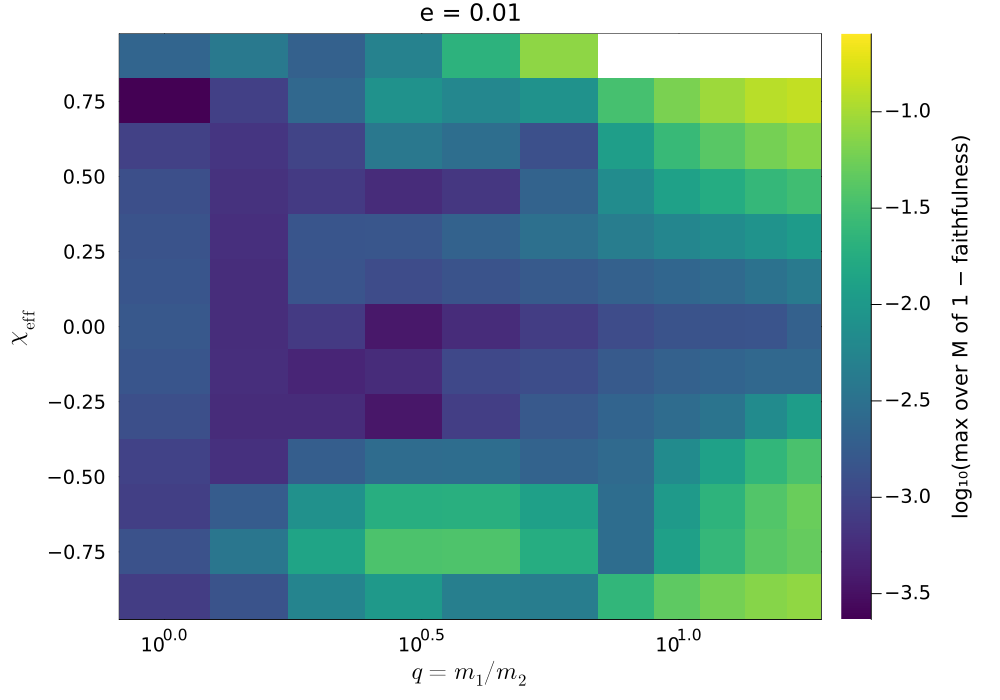

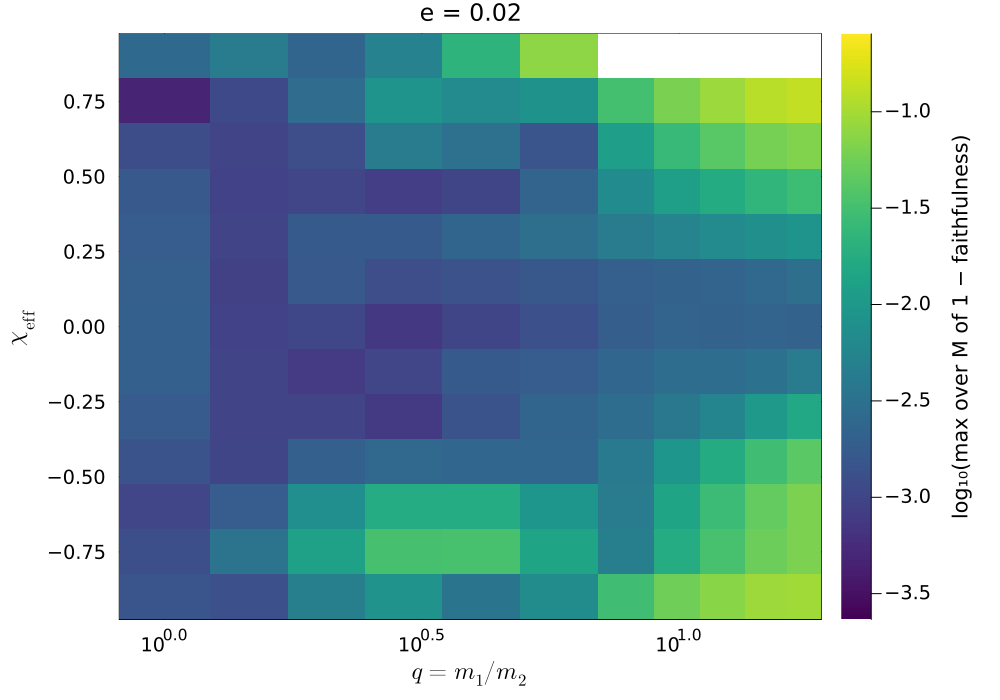

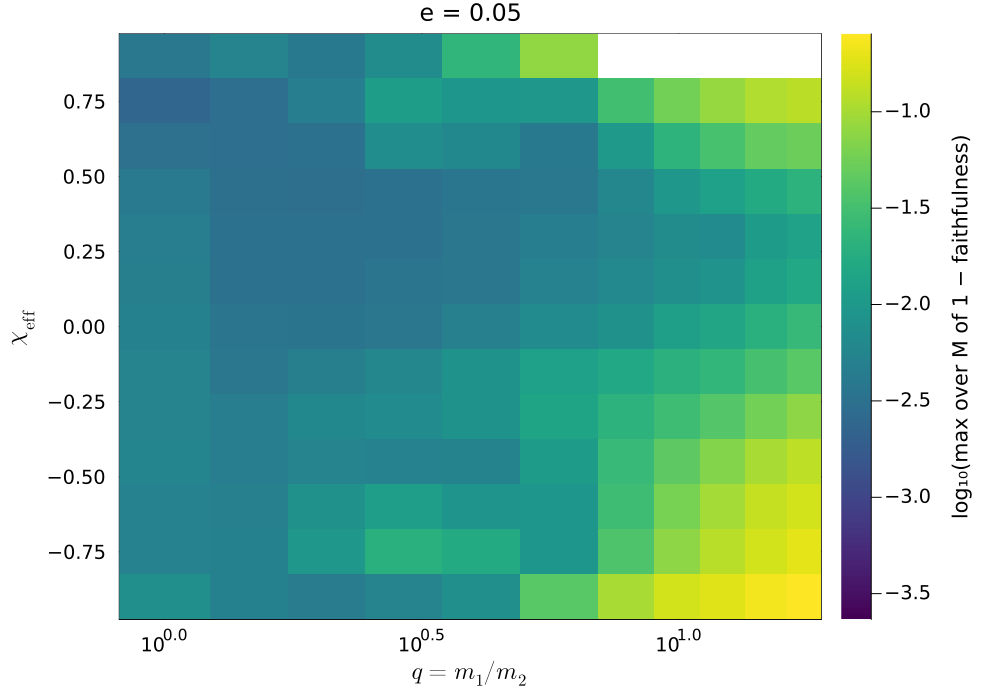

In [ ]:
# one map per eccentricity, same colour scale for the three
all_z = vcat([filter(!isnan, vec(zmax_ecc[e])) for e in e_list_ecc]...)
clims_ecc = (log10(minimum(all_z)), log10(maximum(all_z)))

for e in e_list_ecc
    p = heatmap(qs_ecc, chis_ecc, log10.(zmax_ecc[e]), c = :viridis, clims = clims_ecc,
                xlabel = L"q = m_1 / m_2", ylabel = L"\chi_\mathrm{eff}", title = "e = $e",
                colorbar_title = "\nlog₁₀(max over M of 1 − faithfulness)",
                xscale = :log10, size = (1000, 700), guidefontsize = 16, tickfontsize = 13, titlefontsize = 16,
                left_margin = 5Plots.mm, bottom_margin = 5Plots.mm, right_margin = 14Plots.mm,
                colorbar_titlefontsize = 14, framestyle = :box)
    display(p)

    savefig(p, "~/Desktop/GW-envs/all_params_$e.png")
end